# 07 &nbsp;Which email should we send, in dollars and risk?

**The question a leader actually asks.** Notebook 06 showed both emails beat sending nothing. But the business can only send one, so the real questions are: *which one*, *how sure are we*, and *what does it cost us if we pick wrong?*

**The rule, set before looking (notebook 02).** Choose the option with the highest expected profit per 1,000 emails, and ship it only if:

- it has at least an **80% chance of being the best** option, and
- the **expected loss** of choosing it is at most **$10 per 1,000 emails**.

Otherwise keep sending nothing and extend the test.

**How uncertainty is measured.** The **Bayesian bootstrap** reweights the real customers at random thousands of times. Each reweighting gives a plausible value for each group's average, without assuming a bell curve. Notebook 03 showed resampling methods behave on this data at this size. Each draw is turned into profit using the plan's margin and email cost.

In [1]:
import numpy as np
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.decision import apply_rule, decision_table, lift_draws, profit_draws, sensitivity
from exptoolkit.spec import load_spec

style.use_style()
spec = load_spec("hillstrom_email.yaml")
econ, rule = spec.economics, spec.decision_rule["ship_if"]
df = load_hillstrom()

draws = profit_draws(df, spec, n_draws=4000, seed=1)
table = decision_table(draws)
decision = apply_rule(table, spec)

## 1. Expected profit, chance of being best, and the cost of being wrong

In [2]:
shown = table.rename(index=style.ARM_LABELS)
shown.columns = ["Expected profit", "Low (2.5%)", "High (97.5%)", "Chance best", "Expected loss"]
shown.style.format({
    "Expected profit": "${:,.0f}", "Low (2.5%)": "${:,.0f}", "High (97.5%)": "${:,.0f}",
    "Chance best": "{:.1%}", "Expected loss": "${:,.2f}",
})

,Expected profit,Low (2.5%),High (97.5%),Chance best,Expected loss
No email,$0,$0,$0,0.0%,$249.76
Men's email,$250,$153,$351,98.8%,$0.20
Women's email,$128,$39,$217,1.2%,$121.39


All money is **profit per 1,000 emails**, compared with sending nothing.

**Expected loss** is the question behind every "are we sure?": averaged over everything the data says could be true, how much profit would we give up by picking this option instead of whichever one is really best? For the men's email it is a matter of cents.

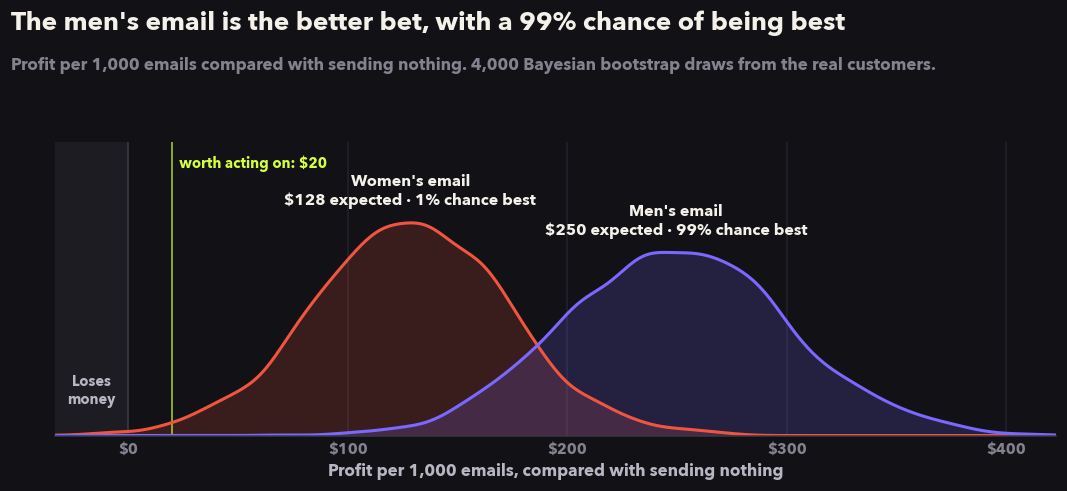

In [3]:
fig, ax = plots.profit_distribution_plot(draws, table, econ.min_profit_per_1000)
style.headline(
    fig,
    f"The men's email is the better bet, with a {table.loc['mens_email', 'prob_best']:.0%} chance of being best",
    "Profit per 1,000 emails compared with sending nothing. 4,000 Bayesian bootstrap draws from the real customers.",
)
style.save(fig, "profit_distribution")

In [4]:
print(f"Choice:          {style.ARM_LABELS[decision['choice']]}")
print(f"Chance best:     {decision['prob_best']:.1%}   (rule: at least {rule['probability_best_at_least']:.0%})")
print(f"Expected loss:   ${decision['expected_loss']:.2f} per 1,000 emails   "
      f"(rule: at most ${rule['expected_loss_per_1000_at_most']:,.0f})")
print(f"Decision:        {'SHIP' if decision['ship'] else 'KEEP TESTING'}")

Choice:          Men's email
Chance best:     98.8%   (rule: at least 80%)
Expected loss:   $0.20 per 1,000 emails   (rule: at most $10)
Decision:        SHIP


## 2. Would the answer change if our assumptions are wrong?

The 35% margin and $0.02 per email are assumptions. A decision that flips when they move a little is fragile. So the rule is re-run across a wide range: margins from 10% to 60%, and email costs from nothing to 30 cents (a very generous allowance for list fatigue).

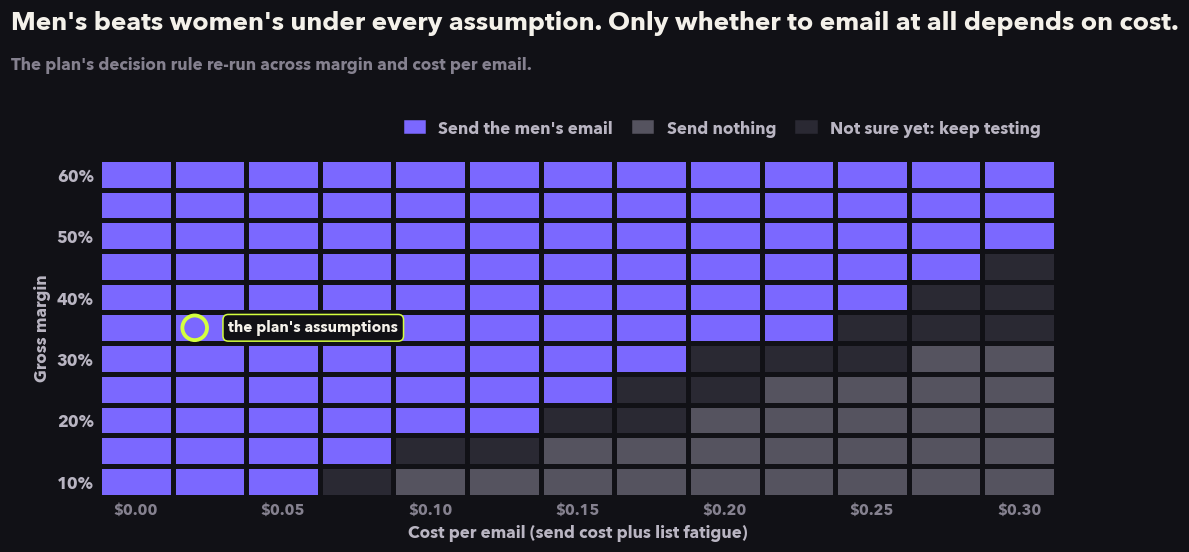

In [5]:
lifts = lift_draws(df, spec, n_draws=4000, seed=1)
margins = np.round(np.arange(0.10, 0.601, 0.05), 2)
costs = np.round(np.arange(0.0, 0.301, 0.025), 3)
sens = sensitivity(lifts, spec.control_arm, margins, costs,
                   rule["probability_best_at_least"], rule["expected_loss_per_1000_at_most"])

fig, ax = plots.sensitivity_map_plot(sens, econ.gross_margin, econ.cost_per_email)
style.headline(fig, "Men's beats women's under every assumption. Only whether to email at all depends on cost.",
               "The plan's decision rule re-run across margin and cost per email.")
style.save(fig, "sensitivity")

In [6]:
at_plan_margin = sens[(sens["margin"] == econ.gross_margin) & (sens["choice"] == "mens_email") & sens["ship"]]
max_cost = at_plan_margin["cost"].max()
print(f"Women's email chosen in {(sens['choice'] == 'womens_email').sum()} of {len(sens)} scenarios")
print(f"At a {econ.gross_margin:.0%} margin, sending the men's email holds up to {100 * max_cost:.1f} cents per email")

Women's email chosen in 0 of 143 scenarios
At a 35% margin, sending the men's email holds up to 22.5 cents per email


**The choice between the two emails never flips.** In every one of the 143 scenarios, the men's email beats the women's. The only thing the assumptions change is whether emailing is worth it at all: if each email effectively cost more than about 22.5 cents at the plan's margin (or less at thinner margins), the safest call becomes "send nothing" or "keep testing". The plan's 2 cents is far from that edge.

## 3. The decision memo

The notebook writes a one-page memo for the decision owner, with every number taken from the analysis above: [`reports/decision_memo.md`](../reports/decision_memo.md).

In [7]:
m, w = table.loc["mens_email"], table.loc["womens_email"]
memo = f"""# Decision memo: Hillstrom email test

**Decision: send the men's email** to customers like the ones in this test (people who bought in the past year).

## Why

- **It makes money.** Expected profit is **${m['expected_profit']:,.0f} per 1,000 emails** compared with sending nothing (plausible range ${m['profit_low']:,.0f} to ${m['profit_high']:,.0f}).
- **It is the better of the two emails.** It has a **{m['prob_best']:.0%} chance** of being the best option.
- **Being wrong would cost almost nothing.** The expected loss from choosing it is **${m['expected_loss']:.2f} per 1,000 emails**.
- **It passes the rule set before the results were seen:** at least {rule['probability_best_at_least']:.0%} chance of being best, and at most ${rule['expected_loss_per_1000_at_most']:,.0f} expected loss per 1,000 emails.

## Options compared

| Option | Expected profit per 1,000 emails | Chance best | Expected loss per 1,000 emails |
|---|---|---|---|
| Men's email | ${m['expected_profit']:,.0f} | {m['prob_best']:.0%} | ${m['expected_loss']:.2f} |
| Women's email | ${w['expected_profit']:,.0f} | {w['prob_best']:.0%} | ${w['expected_loss']:,.0f} |
| No email | $0 | {table.loc['control', 'prob_best']:.0%} | ${table.loc['control', 'expected_loss']:,.0f} |

## How robust it is

- The men's email beats the women's under **every** margin (10% to 60%) and email cost (0 to 30 cents) tested.
- At the assumed {econ.gross_margin:.0%} margin, emailing stays worth it up to about **{100 * max_cost:.1f} cents per email**. The assumed cost is ${econ.cost_per_email:.2f}.

## What this does not cover

- **Unsubscribes were not measured.** A rise in unsubscribes could outweigh the revenue. Check them in the first send.
- **Two weeks only.** Longer-term effects on repeat buying are unknown.
- **Margin and email cost are assumptions.** The decision holds across a wide range, but should be confirmed with finance.

## Next

- Find out who the email actually changes, so it can go only to the customers it helps (notebook 08).
- In the next test, log each customer's spend in the weeks before the send, so variance reduction can work.
"""
with open("../reports/decision_memo.md", "w") as f:
    f.write(memo)
print(memo)

# Decision memo: Hillstrom email test

**Decision: send the men's email** to customers like the ones in this test (people who bought in the past year).

## Why

- **It makes money.** Expected profit is **$250 per 1,000 emails** compared with sending nothing (plausible range $153 to $351).
- **It is the better of the two emails.** It has a **99% chance** of being the best option.
- **Being wrong would cost almost nothing.** The expected loss from choosing it is **$0.20 per 1,000 emails**.
- **It passes the rule set before the results were seen:** at least 80% chance of being best, and at most $10 expected loss per 1,000 emails.

## Options compared

| Option | Expected profit per 1,000 emails | Chance best | Expected loss per 1,000 emails |
|---|---|---|---|
| Men's email | $250 | 99% | $0.20 |
| Women's email | $128 | 1% | $121 |
| No email | $0 | 0% | $250 |

## How robust it is

- The men's email beats the women's under **every** margin (10% to 60%) and email cost (0 to 30 cents) tes